# Week 10 – Genetic algorithms with PyGAD
**COS30018 Intelligent Systems · Anas Al Azad**

A **genetic algorithm (GA)** solves a problem the way evolution does: start with a random *population* of answers, score each one with a **fitness function**, let the best ones be **parents**, mix them (**crossover**), change a few genes at random (**mutation**), and repeat for many **generations**.

1. PyGAD basics (the 4 steps)
2. Fitting a linear model – the sheet's example + my own tuning experiments
3. The 8 Queen puzzle – the GA from `8_queen_puzzle.py` without the GUI, run many times, plus two improvements

(The Kivy app itself is `8_queen_puzzle.py` – run it with `python 8_queen_puzzle.py`.)

In [1]:
import ast
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy
import pandas as pd
import pygad

warnings.filterwarnings("ignore", message="keep_elitism")      # explained in part 2
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
results = {"pygad": pygad.__version__}
print("PyGAD version:", pygad.__version__)

PyGAD version: 3.8.1


## 1. PyGAD basics
The 4 steps from the sheet: (1) write a fitness function, (2) choose the parameters, (3) create `pygad.GA`, (4) `run()`.
In PyGAD 3 the fitness function gets **three** inputs: `(ga_instance, solution, solution_idx)` – the sheet's two-input version crashes (see part 2). Here's the sheet's "fitness = sum of the solution" idea on a population of 3 solutions I made up:

In [2]:
population = numpy.array([[100, 200, 300, 150],
                       [400, 250, 200, 99],
                       [10, 3, 200, 50]])


def fitness_sum(ga_instance, solution, solution_idx):
    return numpy.sum(solution)


for i, sol in enumerate(population):
    print(f"solution {i}: {sol} -> fitness {fitness_sum(None, sol, i)}")
print("A higher fitness = a better solution, so solution 1 is most likely to become a parent.")

solution 0: [100 200 300 150] -> fitness 750
solution 1: [400 250 200  99] -> fitness 949
solution 2: [ 10   3 200  50] -> fitness 263
A higher fitness = a better solution, so solution 1 is most likely to become a parent.


## 2. Fitting a linear model
Find 6 weights so that  y = w1·4 + w2·(−2) + w3·3.5 + w4·5 + w5·(−11) + w6·(−4.7) = 44.
Fitness = 1 / |output − 44| – the closer to 44, the bigger the fitness. Same parameters as the sheet; `random_seed` added so my run can be repeated.

In [3]:
function_inputs = [4, -2, 3.5, 5, -11, -4.7]
desired_output = 44


def fitness_func(ga_instance, solution, solution_idx):      # (my fix) 3 inputs for PyGAD 3
    output = numpy.sum(solution * function_inputs)
    fitness = 1.0 / numpy.abs(output - desired_output)
    return fitness


SHEET = dict(num_generations=50, num_parents_mating=4, sol_per_pop=8, num_genes=len(function_inputs),
             init_range_low=-2, init_range_high=5, parent_selection_type="sss", keep_parents=1,
             crossover_type="single_point", mutation_type="random", mutation_percent_genes=10)


def run_linear(seed, **changes):
    params = dict(SHEET, **changes)
    ga = pygad.GA(fitness_func=fitness_func, random_seed=seed, suppress_warnings=True, **params)
    ga.run()
    solution, solution_fitness, solution_idx = ga.best_solution()
    prediction = numpy.sum(numpy.array(function_inputs) * solution)
    return ga, solution, solution_fitness, solution_idx, prediction


ga_instance, solution, solution_fitness, solution_idx, prediction = run_linear(seed=10)
print("Parameters of the best solution:", solution)
print("Fitness value of the best solution =", solution_fitness)
print("Index of the best solution :", solution_idx)
print("Predicted output based on the best solution :", prediction)
if ga_instance.best_solution_generation != -1:
    print("Best fitness value reached after", ga_instance.best_solution_generation, "generations.")

results["linear_main"] = {"seed": 10, "weights": [round(float(w), 4) for w in solution],
                          "fitness": round(float(solution_fitness), 2), "prediction": round(float(prediction), 4),
                          "error": round(abs(float(prediction) - 44), 4),
                          "best_generation": int(ga_instance.best_solution_generation)}

Parameters of the best solution: [ 3.63656238  1.65153007  4.47357854  0.01075153 -1.36678456 -0.42642348]
Fitness value of the best solution = 149.0843692599316
Index of the best solution : 0
Predicted output based on the best solution : 43.99329238869934
Best fitness value reached after 4 generations.


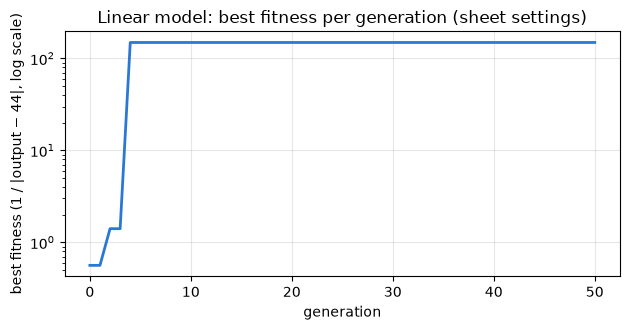

error went from 1.78 (generation 0) to 0.0067 at generation 4, then didn't improve for the other 46 generations


In [4]:
# the sheet's plot_result() is called plot_fitness() in PyGAD 3 - I draw it myself so I can save it
fit = ga_instance.best_solutions_fitness
plt.figure(figsize=(6.4, 3.4))
plt.plot(range(len(fit)), fit, color="#2a78d6", linewidth=2)
plt.yscale("log")
plt.xlabel("generation")
plt.ylabel("best fitness (1 / |output − 44|, log scale)")
plt.title("Linear model: best fitness per generation (sheet settings)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figures/10_1_linear_fitness.png", dpi=150)
plt.show()
best_gen = int(numpy.argmax(fit))
print(f"error went from {1 / fit[0]:.2f} (generation 0) to {1 / fit[best_gen]:.4f} at generation {best_gen}, "
      f"then didn't improve for the other {len(fit) - 1 - best_gen} generations")
results["linear_main"]["start_error"] = round(1 / fit[0], 2)
results["linear_main"]["stuck_generations"] = len(fit) - 1 - best_gen

**Is the answer unique?** No – one equation, six unknowns, so there are endless weight sets that give 44. Two different seeds:

In [5]:
for seed in (1, 2):
    _, sol, f, _, pred = run_linear(seed)
    print(f"seed {seed}: weights {numpy.round(sol, 2)} -> output {pred:.4f}")
results["not_unique"] = True

seed 1: weights [ 0.61 -0.31  4.58  4.71  0.26 -0.89] -> output 43.9795
seed 2: weights [ 3.93 -1.04  3.39  1.43 -0.34 -0.74] -> output 43.9992


### My experiments – tuning the GA
Because a GA is random, one run says little, so each setting is run with **20 different seeds** and I look at the median error |output − 44| and how often it gets within 0.01.

In [6]:
SEEDS = range(20)
settings = {
    "sheet (50 gen, 8 per pop)": {},
    "200 generations": dict(num_generations=200),
    "50 per population": dict(sol_per_pop=50, num_parents_mating=10),
    "both (200 gen, 50 per pop)": dict(num_generations=200, sol_per_pop=50, num_parents_mating=10),
    "tournament selection": dict(parent_selection_type="tournament"),
    "roulette wheel selection": dict(parent_selection_type="rws"),
    "uniform crossover": dict(crossover_type="uniform"),
    "mutate 50% of genes": dict(mutation_percent_genes=50),
}
rows = []
for name, changes in settings.items():
    t = time.time()
    errors, gens = [], []
    for s in SEEDS:
        ga, sol, f, _, pred = run_linear(s, **changes)
        errors.append(abs(pred - desired_output))
        gens.append(ga.best_solution_generation)
    rows.append({"setting": name, "median error": round(float(numpy.median(errors)), 4),
                 "worst error": round(float(max(errors)), 4),
                 "within 0.01": f"{sum(e < 0.01 for e in errors)}/{len(errors)}",
                 "seconds (20 runs)": round(time.time() - t, 1)})
tuning = pd.DataFrame(rows).set_index("setting")
results["linear_tuning"] = rows
tuning

,median error,worst error,within 0.01,seconds (20 runs)
setting,,,,
"sheet (50 gen, 8 per pop)",0.0073,0.0331,14/20,0.7
200 generations,0.0013,0.0133,19/20,1.7
50 per population,0.0016,0.0079,20/20,2.4
"both (200 gen, 50 per pop)",0.0003,0.0012,20/20,9.4
tournament selection,0.0094,0.0482,10/20,0.5
roulette wheel selection,0.0112,0.0601,8/20,0.4
uniform crossover,0.0145,0.0348,8/20,0.4
mutate 50% of genes,0.0294,0.0994,6/20,0.8


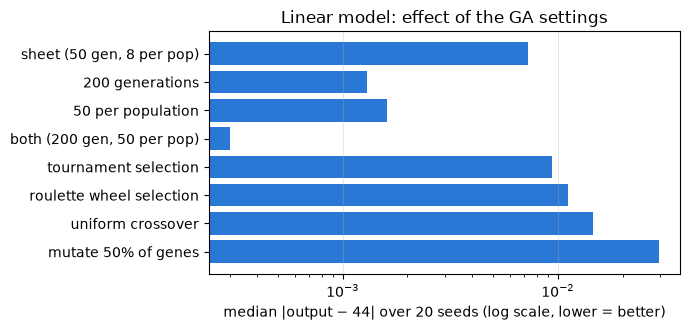

In [7]:
plt.figure(figsize=(7, 3.4))
plt.barh(tuning.index[::-1], tuning["median error"][::-1], color="#2a78d6")
plt.xscale("log")
plt.xlabel("median |output − 44| over 20 seeds (log scale, lower = better)")
plt.title("Linear model: effect of the GA settings")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("figures/10_2_linear_tuning.png", dpi=150)
plt.show()

## 3. The 8 Queen puzzle
Each solution = 8 numbers, the column of the queen in each row (so there's never more than one queen per row). Fitness = 1 / (number of attacks), or **1.1** when there are no attacks.
I load the fitness functions straight out of `8_queen_puzzle.py` (without starting the Kivy window), so this is exactly the code the app uses.

In [8]:
def load_functions(path):
    tree = ast.parse(Path(path).read_text())
    wanted = ("fitness", "attacks_diagonal", "diagonal_attacks", "attacks_column")
    module = ast.Module(body=[n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in wanted],
                        type_ignores=[])
    ns = {"numpy": numpy}
    exec(compile(module, path, "exec"), ns)
    return ns["fitness"]


fitness = load_functions("8_queen_puzzle.py")


def attacks(board):
    f = fitness(None, numpy.array(board, dtype=float), 0)
    return 0 if f > 1 else round(1 / f, 2)


print("all on one diagonal [0..7]:", attacks([0, 1, 2, 3, 4, 5, 6, 7]), "attacks (28 pairs of queens)")
print("a real solution [0,4,7,5,2,6,1,3]:", attacks([0, 4, 7, 5, 2, 6, 1, 3]), "attacks")

all on one diagonal [0..7]: 28.0 attacks (28 pairs of queens)
a real solution [0,4,7,5,2,6,1,3]: 0 attacks


**A bug I found in the tutor's code:** in `attacks_diagonal` the running total was never reset for each queen, so it was added again and again. The original version says the all-on-one-diagonal board has **126** attacks instead of 28. I fixed it in `8_queen_puzzle.py` (marked *my fix*). Comparing both versions:

In [9]:
ORIGINAL = Path("8_queen_puzzle.py").read_text().replace(
    "        total = 0  # (my fix)", "        pass  # original: no reset  # (my fix)")
Path("results/_original_queens.py").write_text(ORIGINAL)
fitness_original = load_functions("results/_original_queens.py")
Path("results/_original_queens.py").unlink()
for board in ([0, 1, 2, 3, 4, 5, 6, 7], [1, 3, 0, 2, 4, 6, 5, 7]):
    fo = fitness_original(None, numpy.array(board, float), 0)
    print(f"{board}: original code says {1 / fo:.0f} attacks, fixed code says {attacks(board)}")

[0, 1, 2, 3, 4, 5, 6, 7]: original code says 126 attacks, fixed code says 28.0
[1, 3, 0, 2, 4, 6, 5, 7]: original code says 14 attacks, fixed code says 4.0


### Running the app's GA without the GUI
Same settings as `initialize_population()` in the app: 100 random boards, 100 generations, 30 parents, random mutation of 2 genes. I run it with **30 different seeds** and count how often it finds a board with 0 attacks. Then two changes of my own:
* **integer genes** (`gene_space=range(8)`) – in the app, crossover/mutation make genes like 3.7 which the board just rounds down;
* **permutation** – every column used exactly once (`allow_duplicate_genes=False` + swap mutation), so column attacks are impossible and only diagonals are left.

In [10]:
def random_boards(seed, n=100, permutation=False):
    rng = numpy.random.default_rng(seed)
    if permutation:
        return numpy.array([rng.permutation(8) for _ in range(n)], dtype=float)
    return (rng.random((n, 8)) * 8).astype(numpy.uint8).astype(float)


def run_queens(seed, fit, variant="app"):
    common = dict(num_generations=100, num_parents_mating=30, fitness_func=fit, random_seed=seed,
                  stop_criteria="reach_1.1", suppress_warnings=True)
    if variant == "app":                       # the settings from 8_queen_puzzle.py
        ga = pygad.GA(initial_population=random_boards(seed), mutation_percent_genes=0.01, mutation_type="random",
                      mutation_num_genes=2, mutation_by_replacement=True, random_mutation_min_val=0.0,
                      random_mutation_max_val=8.0, **common)
    elif variant == "integer genes":
        ga = pygad.GA(initial_population=random_boards(seed), gene_space=list(range(8)), gene_type=int,
                      mutation_type="random", mutation_num_genes=2, **common)
    else:                                      # permutation
        ga = pygad.GA(initial_population=random_boards(seed, permutation=True), gene_space=list(range(8)),
                      gene_type=int, allow_duplicate_genes=False, mutation_type="swap", **common)
    t = time.time()
    ga.run()
    sol, f, _ = ga.best_solution()
    return {"solved": bool(f > 1.05), "generations": ga.generations_completed,
            "attacks_left": 0 if f > 1.05 else round(1 / f, 2), "seconds": time.time() - t,
            "board": [int(x) for x in sol]}


QSEEDS = range(30)
variants = [("app settings, original attack count", fitness_original, "app"),
            ("app settings, fixed attack count", fitness, "app"),
            ("integer genes (my change)", fitness, "integer genes"),
            ("permutation (my change)", fitness, "permutation")]
queen_rows, queen_runs = [], {}
for name, fit, variant in variants:
    runs = [run_queens(s, fit, variant) for s in QSEEDS]
    queen_runs[name] = runs
    solved = [r for r in runs if r["solved"]]
    queen_rows.append({"version": name, "solved": f"{len(solved)}/{len(runs)}",
                       "solved %": round(100 * len(solved) / len(runs)),
                       "median generations when solved": int(numpy.median([r["generations"] for r in solved])) if solved else None,
                       "avg seconds per run": round(numpy.mean([r["seconds"] for r in runs]), 2)})
queens = pd.DataFrame(queen_rows).set_index("version")
results["queens"] = queen_rows
queens

,solved,solved %,median generations when solved,avg seconds per run
version,,,,
"app settings, original attack count",14/30,47,60,1.32
"app settings, fixed attack count",20/30,67,55,1.19
integer genes (my change),13/30,43,71,1.27
permutation (my change),30/30,100,1,0.10


In [11]:
# how much of the permutation result is luck? - a random start that already contains a 0-attack board
def true_attacks(b):
    b = [int(x) for x in b]
    return sum(1 for i in range(8) for j in range(i + 1, 8) if b[i] == b[j] or abs(b[i] - b[j]) == j - i)


lucky = sum(any(true_attacks(p) == 0 for p in random_boards(s, permutation=True)) for s in QSEEDS)
lucky_app = sum(any(true_attacks(p) == 0 for p in random_boards(s)) for s in QSEEDS)
print(f"random starting populations that already contained a solution: permutation {lucky}/30, app-style {lucky_app}/30")
results["queens_lucky_start"] = {"permutation": lucky, "app": lucky_app}

random starting populations that already contained a solution: permutation 8/30, app-style 0/30


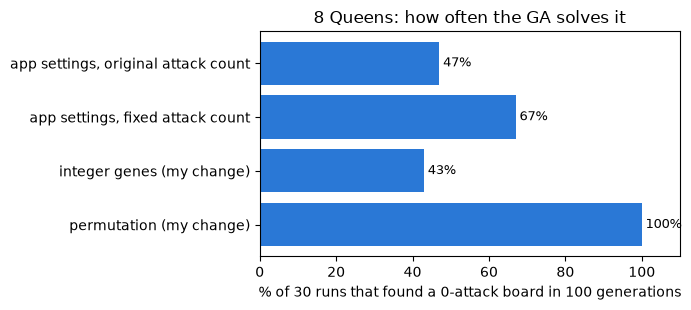

In [12]:
plt.figure(figsize=(7, 3.2))
plt.barh(queens.index[::-1], queens["solved %"][::-1], color="#2a78d6")
for y, v in enumerate(queens["solved %"][::-1]):
    plt.text(v + 1, y, f"{v}%", va="center", fontsize=9)
plt.xlim(0, 110)
plt.xlabel("% of 30 runs that found a 0-attack board in 100 generations")
plt.title("8 Queens: how often the GA solves it")
plt.tight_layout()
plt.savefig("figures/10_3_queens_success.png", dpi=150)
plt.show()

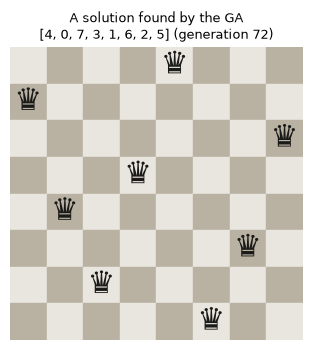

saved results/lab10_results.json


In [13]:
first = next(r for r in queen_runs["app settings, fixed attack count"] if r["solved"])
board = first["board"]
fig, ax = plt.subplots(figsize=(3.6, 3.6))
for r in range(8):
    for c in range(8):
        ax.add_patch(plt.Rectangle((c, 7 - r), 1, 1, color="#e9e6df" if (r + c) % 2 == 0 else "#b9b2a3"))
    ax.text(board[r] + 0.5, 7 - r + 0.5, "♛", ha="center", va="center", fontsize=22, color="#1a1a19")
ax.set_xlim(0, 8); ax.set_ylim(0, 8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"A solution found by the GA\n{board} (generation {first['generations']})", fontsize=9)
plt.tight_layout()
plt.savefig("figures/10_4_queens_board.png", dpi=150)
plt.show()
results["queens_example"] = {"board": board, "generations": first["generations"]}
with open("results/lab10_results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)
print("saved results/lab10_results.json")